# SECT-4451 — Lecture 2 Practical: Data Exploration & Foundational Math

Student performance dataset (generated with the provided code, `seed=42`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan   # Missing values
df.loc[99, 'study_hours'] = 50        # Outlier
df.loc[98, 'attendance'] = -10        # Impossible value

df.to_csv('student_data.csv', index=False)
print(df.shape)
df.head(10)

(100, 4)


,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473
5,NaN,89.040509,55.932624,40.751177
6,8.158426,103.861859,77.725529,57.171201
7,6.534869,86.745778,77.706789,41.874669
8,4.061051,87.575504,77.725715,46.583807
9,6.085120,84.255541,127.790972,52.866454


## Part A — Inspect and Clean

In [2]:
print(df.isna().sum())
print()
print(df.describe().round(2))
print()
print("Top 3 study_hours values:", df['study_hours'].dropna().sort_values().tail(3).round(2).values)

study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64

       study_hours  attendance  previous_mark  final_score
count        94.00      100.00         100.00       100.00
mean          5.22       84.27          70.97        42.69
std           5.01       13.48          16.26         6.09
min          -0.24      -10.00          21.38        29.16
25%           3.73       76.83          60.17        38.19
50%           4.81       85.84          71.47        42.76
75%           5.74       90.38          80.57        46.69
max          50.00      112.20         127.79        57.17

Top 3 study_hours values: [ 8.16  8.7  50.  ]


**A1. Outlier in `study_hours`.** One student has 50 study hours, while the next highest value is about 8.7.
Fifty hours is not plausible for a single day and is almost certainly a data-entry error, so I **removed** that row
rather than capping it. Capping would still leave an invented value in the data.

I also handled the other two problems in the dataset:
- **6 missing `study_hours` values** (rows 0–5): dropped, since only 6 of 100 rows are affected and imputing would add made-up values.
- **`attendance = -10`** (row 98): an impossible value for an attendance percentage, so that row was dropped too.

In [3]:
clean = df.dropna(subset=['study_hours'])      # missing values
clean = clean[clean['study_hours'] < 50]       # outlier
clean = clean[clean['attendance'] >= 0]        # impossible attendance
clean = clean.reset_index(drop=True)

print("Rows before:", len(df), "| Rows after:", len(clean))

Rows before: 100 | Rows after: 92


**A2. Shape and columns.** The feature matrix **X** has the 3 feature columns and the target is `final_score`.
All 4 columns are numerical (continuous). The target variable is **`final_score`**.

In [4]:
X = clean[['study_hours', 'attendance', 'previous_mark']]
y = clean['final_score']
print("Feature matrix X shape:", X.shape)
print("Target y shape:", y.shape)
print("Numerical columns:", list(clean.select_dtypes(include='number').columns))
print("Target variable: final_score")

Feature matrix X shape: (92, 3)
Target y shape: (92,)
Numerical columns: ['study_hours', 'attendance', 'previous_mark', 'final_score']
Target variable: final_score


## Part B — Summarize

In [5]:
summary = clean.agg(['mean', 'median', 'std']).round(2)
summary

,study_hours,attendance,previous_mark,final_score
mean,4.73,85.66,70.70,42.72
median,4.70,86.74,71.01,42.76
std,1.85,9.68,16.50,6.20


**B2. Observations**

1. `previous_mark` has by far the largest standard deviation (about 16.5), so students' earlier performance varies a lot, while `study_hours` has a small spread (about 1.9 hours), so most students study a similar amount.
2. For every column the mean and median are very close, which suggests the distributions are roughly symmetric with no strong skew once the outlier is removed.
3. `attendance` averages about 86% with a standard deviation of roughly 10, so most students attend regularly, though a few have noticeably lower attendance.

## Part C — Visualize

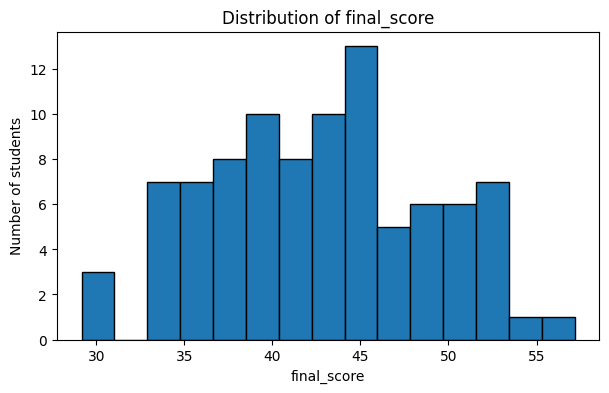

In [6]:
plt.figure(figsize=(7, 4))
plt.hist(clean['final_score'], bins=15, edgecolor='black')
plt.title('Distribution of final_score')
plt.xlabel('final_score')
plt.ylabel('Number of students')
plt.show()

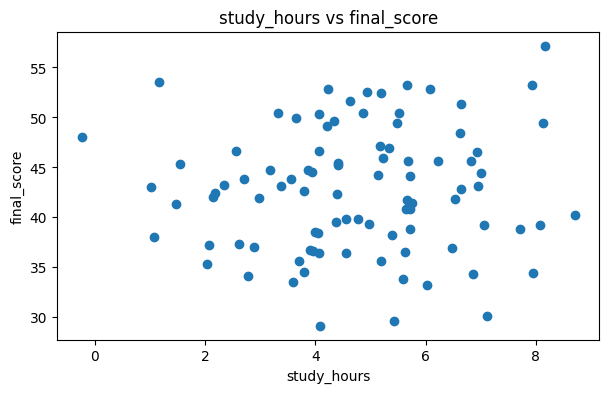

In [7]:
plt.figure(figsize=(7, 4))
plt.scatter(clean['study_hours'], clean['final_score'])
plt.title('study_hours vs final_score')
plt.xlabel('study_hours')
plt.ylabel('final_score')
plt.show()

**C2. Trend.** The scatter plot shows a very weak relationship: the points form a diffuse cloud with almost no visible upward trend.
More study hours does not clearly mean a higher final score in this data.

## Part D — Correlation and Causality

In [8]:
r = clean['study_hours'].corr(clean['final_score'])   # Pearson by default
print("Pearson r (study_hours, final_score):", round(r, 3))

Pearson r (study_hours, final_score): 0.051


**D2. Critical thinking.**

- **No, correlation does not guarantee a specific score.** Correlation describes a general tendency across many students, not a rule for one individual. Here r is close to 0, so knowing someone studies 10 hours tells us almost nothing certain about their score. Individual results also vary because of noise.
- **Lurking / confounding variable:** a student's **prior ability or previous marks** could explain the link. Students who already perform well may both study more and score higher, so study time would appear related to scores without being the cause. Attendance or motivation could play a similar role.

## Part E — Vectors and Dot Product

In [9]:
x = clean[['study_hours', 'attendance', 'previous_mark']].iloc[0].values
w = np.array([0.5, 0.2, 0.4])
b = 5

y_hat = np.dot(w, x) + b
print("x =", x.round(2))
print("w =", w)
print("y = w . x + b =", round(y_hat, 2))

x = [  8.16 103.86  77.73]
w = [0.5 0.2 0.4]
y = w . x + b = 60.94


**E4. Conceptually.**

- **w (weights)** says how much each feature contributes to the predicted score. A larger weight means that feature has more influence, so here `study_hours` counts 0.5 per hour, `attendance` 0.2 per point and `previous_mark` 0.4 per mark.
- **b (bias)** is the baseline prediction when all features are zero. It lets the model shift its output up or down instead of being forced through the origin, so it can fit data where the score is not zero when every input is zero.

## Part F — Scaling

In [10]:
scaled = clean.copy()
for col in ['study_hours', 'previous_mark']:
    scaled[col + '_scaled'] = (clean[col] - clean[col].mean()) / clean[col].std()

print(scaled[['study_hours_scaled', 'previous_mark_scaled']].agg(['mean', 'std']).round(3))
print()
print("Original ranges:")
print("study_hours   :", round(clean['study_hours'].min(), 2), "to", round(clean['study_hours'].max(), 2))
print("previous_mark :", round(clean['previous_mark'].min(), 2), "to", round(clean['previous_mark'].max(), 2))
scaled.head()

      study_hours_scaled  previous_mark_scaled
mean                -0.0                   0.0
std                  1.0                   1.0

Original ranges:
study_hours   : -0.24 to 8.7
previous_mark : 21.38 to 127.79


,study_hours,attendance,previous_mark,final_score,study_hours_scaled,previous_mark_scaled
0,8.158426,103.861859,77.725529,57.171201,1.849892,0.425768
1,6.534869,86.745778,77.706789,41.874669,0.972728,0.424632
2,4.061051,87.575504,77.725715,46.583807,-0.363811,0.425780
3,6.085120,84.255541,127.790972,52.866454,0.729740,3.460863
4,4.073165,65.812288,78.563358,36.404534,-0.357266,0.476560


**F2. Why K-Nearest Neighbors needs scaling.** KNN decides which points are "close" using distances (for example Euclidean distance).
`previous_mark` spans roughly 21 to 128, while `study_hours` spans only about 0 to 9, so differences in `previous_mark` are
many times larger numerically. Without scaling, the distance is dominated by `previous_mark` and `study_hours` is effectively ignored,
even if it were an important feature. Standardizing puts both on the same scale (mean 0, standard deviation 1) so each contributes fairly.